In [1]:
## Libraries
from tqdm import trange
import numpy as np
import matplotlib.pyplot as plt
from Scripts import animationUtils

In [2]:
def V_1(
        x,
        k : float       = 1,
        N_x : float     = 100,
        alpha : float   = 0.8
        ) : 
    """
    params:
        x:      Arraylike med heltallsposisjoner
        k:      konstant som tilsvarer k * beta
        N_x:    antall binding sites i én periode
        alpha:  konstant
    return:
        pot:    Potentialet V_1
    """
    x_modN =x%N_x

    pot = -k*(x_modN-N_x)/((1 - alpha)*N_x)
    pot[x_modN <= alpha * N_x]  =(k * x_modN/(alpha * N_x))[x_modN <= alpha * N_x]

    return pot
    
def V_2(x,k, *args) -> int:
    return np.full_like(x,k)

In [3]:
def probabilities(
        V ,
        x_0,
        k : float,
        N_x : float,
        alpha : float
        ) -> tuple[np.ndarray, np.ndarray] : 
    """
    params:
        V:    potensialfunksjonen sannsynlighetene beregnes ut ifra
        x_0:      ArrayLike med posisjoner, hvis sannsynlighet for forflyttning skal finnes
        *args:  parameterene som potensialet tar inn
    returns:
        
    """

    pot_minus = V(x_0 - 1, k, N_x, alpha)
    pot_zero  = V(x_0, k, N_x, alpha)
    pot_plus  = V(x_0 + 1, k, N_x, alpha)

    p_minus = (1 + np.exp(pot_minus - pot_plus) + np.exp(pot_minus - pot_zero))**-1
    p_plus = (1 + np.exp(pot_plus - pot_zero) + np.exp(pot_plus - pot_minus))**-1
    
    return p_minus, p_plus

# Oppgave 4
Først for at koden fra oppgave 3 skulle funke for oppgave 4, måtte vi gjør en liten justering. Stort sett innbar det kun å legge til denne random_step funksjonen som er definert under. Den tar inn arrayet med posisjonene for et tidsteg og gjør random walk simuleringen for et tidsteg. I tillegg, som ønsket, sørger den for at partiklene ikke koliderer. Dette kommer fra leddene etter and i if setningen. I tillegg trengtes det å redfinere simulate funksjonen litt for at den skal kunne ta inn b.

In [24]:
def random_step4(x,pm,pp,N_x,spatialPeriods,b,h):
    length=len(x)
    #Lager et array med tilfeldige tall for å avgjøre hvilken retning
    r=np.random.rand(length)

    #Lager et array med indexer for x i en tilfeldig rekkefølge
    idx=np.arange(0,length,1)
    np.random.shuffle(idx)
    
    for i in idx:
        if (r[i]<pm[i] and b+h<=abs(x[i]-x[i-1])<=N_x*spatialPeriods-b-h): # Sjekker steg retning og at bevegelse ikke gir kollisjon
            x[i]-=1
        elif (r[i]>(1-pp[i]) and b+h<=abs(x[i-length+1]-x[i])<=N_x*spatialPeriods-b-h):
            x[i]+=1
    return x

In [ ]:

def simulate4(
        startPositions : np.ndarray = np.arange(200),
        alpha : float  = 0.8, 
        T_p : int = 500, 
        N_x : int = 100, 
        N_p : int = 1200,
        k : int  = 1000,
        b : int = 4,
        h: int = 1,
        spatialPeriods : int  = 2,
        cycles : int = 10,
        startV_2 : bool = False,
        random_step = random_step4
        )-> tuple[np.ndarray, np.ndarray, list]:
    """
    params:
        startPositions: array over startposisjoner
        alpha: konstant, forskyver potensialet
        T_p: tidsperiode for en halv syklus
        N_x: romlig periode for potensial
        N_p antall partikler, rundes av til multiplum av antall festepunkter
        k: samlet konstant lik k * beta
        spatialPeriods: antall romlige perioder, gir antall festepunkter som N_p * spatialPeriods
        cycles: antall sykler som skal simuleres
        startV_2: hvis True starter blir V_2 det første potensialet
    returns:
        x: array med sluttposisjoner
        currents: array
        XX: matrise med posisjoner for hvert tidssteg slik at x(t) = X[t]
    """

    
    N = N_x * spatialPeriods #antall festepunkter
    XX = [] 
    x_ref : np.ndarray  = np.arange(N) #referansearray for x-aksen. Verdier samsvarer med indeks for referansearrayer
    

    x_0 : np.ndarray = np.asarray([i for i in startPositions for _ in range(N_p//len(startPositions))]) #array med alle partikler
    XX.append(x_0)

    p_1 = probabilities(V_1, x_ref, k, N_x, alpha)
    p_2 = probabilities(V_2, x_ref, k, N_x , alpha)

    pm_tup = (p_1[0], p_2[0])
    pp_tup = (p_1[1], p_2[1])

    n = np.zeros_like(x_0)

    currents = np.zeros(cycles)
    for c in trange(2 * cycles, ascii = True, desc  = "runnning half-cycles"):
        pm_ref  = pm_tup[c%2 - int(startV_2)]
        pp_ref =  pp_tup[c%2 - int(startV_2)]

        for t in range(T_p):
            x = x_0%N
            pm = np.asarray([pm_ref[i] for i in x])
            pp = np.asarray([pp_ref[i] for i in x])

            ## Den eneste delen som er endre fra oppgave 3
            random_step(x,pm,pp,N_x,spatialPeriods,b,h)    ## Her utføres random step simulering med partikkelinteraksjon

            n += x - x_0%N
            x_0 = x

            XX.append(x_0)
            
        if c%2:
            currents[c//2] = np.mean(n)/(2 * T_p*N_p)
            n = np.zeros_like(x)

    return x, currents, XX

## Oppgave 4a

Her defineres størrelsene som er presisert i oppgaven. 

In [27]:
alpha  = 0.2
T_p= 50
N_x  = 20
k = 1000
b=3
h=1
spatialPeriods = 4
cycles = 5
startV_2  = True
N_p  = 10

Her kjøres simuleringen for 4a


In [28]:
startPositions=np.arange(0,N_x*spatialPeriods,int((N_x*spatialPeriods/N_p)//1))
x, currents, XX=simulate4(startPositions,alpha,T_p,N_x,N_p,k,b,h,spatialPeriods,cycles,startV_2) 

runnning half-cycles: 100%|##########| 10/10 [00:00<00:00, 374.09it/s]


Plotter data

Currents=  [ 0.036  0.04  -0.011  0.051  0.033]


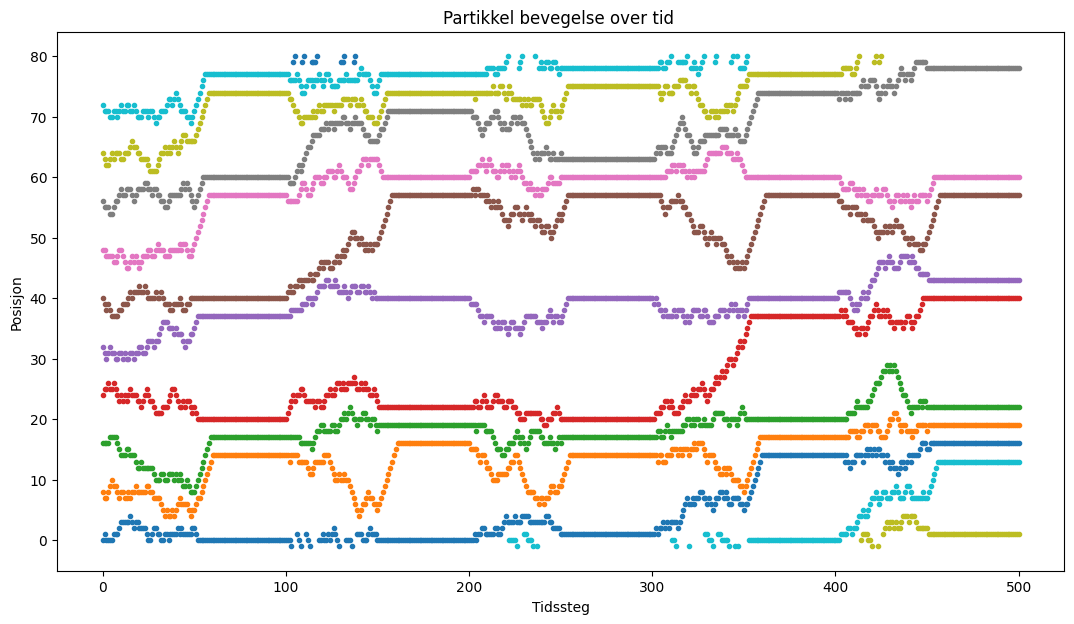

In [29]:

print("Currents= ",currents)

plt.figure(figsize=(13,7))
XX_tranpose=np.transpose(XX)
for i in range(len(XX_tranpose)):
    plt.plot(XX_tranpose[i],".")
plt.title("Partikkel bevegelse over tid ")
plt.ylabel("Posisjon")
plt.xlabel("Tidssteg")
plt.show()

### Diskusjon:
Det første vi la merke til er at partiklene har en tendens til å klumpe seg litt mer opp. Så klart så er jo hovedårsaken til oppklumpingen potensialgropene, som er til stede i simulasjonen uten partikkelinteraksjon, men ser en på plottet over så har flere partikler samlet seg i potensialgropen rundt 20. Vår hypotese er at siden partiklene ikke kan pasere hverandre, så er det ikke så usannsynlig at én partikkel blokkerer alle partiklene bak seg og lager en hopning. I eksempelet over vil dette være den røde partikkelen, som i alle syklene blokkerer den grønne partikkelen fra å hoppe i neste potensial grop, og skaper derfor en opphopning.

En annen effekt med partikkelkollisjonen som vi observerte er at det sjeldent er mer enn en partikkel som klarer å hoppe til neste potensialgrop. Ved høyere T_p og flere partikler vil dette så klart skje oftere, men trenden med at det sjeldnere at flere partikler kommer til neste grop er gjennomskuende (ser mer av det i 4b). Dette virker logisk ettersom den ytterste partikkelen vil blokkere den bak, som videre blokker de bak seg igjen. Derfor blir det slik at den andre partikkelen ofte ikke rekker å komme seg til neste grop fordi flere av stegene dens mot neste grop blir blokkert av partikkelen utenfor. 

Derimot så gjør partikkelkollisjon at den ytterste partikkelen oftere klarer å komme seg til neste grop. Dette er grunnet i den samme effekten som nevnt over, der den ytterste partikkelen oftere kommer seg mot neste grop når det konstante potensialet virker, fordi mange av dens steg tilbake blir blokkert av de andre partiklene som var i samme grop som den. Dette gjør at sannsynligheten for at den ytterste partikkelen kommer seg til neste grop er høyere med partikkelkollisjon enn uten. 

## Oppgave 4b

In [30]:
# Definerer størrelsene som presisert i oppgaven
alpha  = 0.2
T_p= 300
# N_x  = 100 
k = 1000
b=20
h=1
spatialPeriods = 10
cycles = 100
startV_2  = True

Kjører simulasjonen for forskjellige partikkel tettheter mellom 0 og 1

In [31]:
# Lager et array med forskjellige partikkel antall som tilsvarer tetthet fra 0 til 1
N_p= np.ceil(np.linspace(0,1*N_x*spatialPeriods/b,10))

# lager et array for å lagre data
cur_rho=np.zeros_like(N_p)
rho = N_p*b/spatialPeriods/N_x

# Kjører simuleringen for alle partikkel antall og lagrer gjennomsnittlig strøm i cur_rho
for i in range(len(N_p)):
    startPositions=np.int_(np.floor(np.linspace(0,N_x*spatialPeriods,int(N_p[i]))))
    x, currents, XX=simulate4(startPositions,alpha,T_p,N_x,int(N_p[i]),k,b,h,spatialPeriods,cycles,startV_2)
    cur_rho[i]=np.mean(currents)

runnning half-cycles:   0%|          | 0/200 [00:00<?, ?it/s]

c:\Users\alfre\Downloads\Koding\2.trinn\TMA4320-Vitber\prosjekt2-alfredgs-gauteod\.venv\Lib\site-packages\numpy\_core\fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\alfre\Downloads\Koding\2.trinn\TMA4320-Vitber\prosjekt2-alfredgs-gauteod\.venv\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
runnning half-cycles: 100%|##########| 200/200 [00:02<00:00, 72.46it/s]


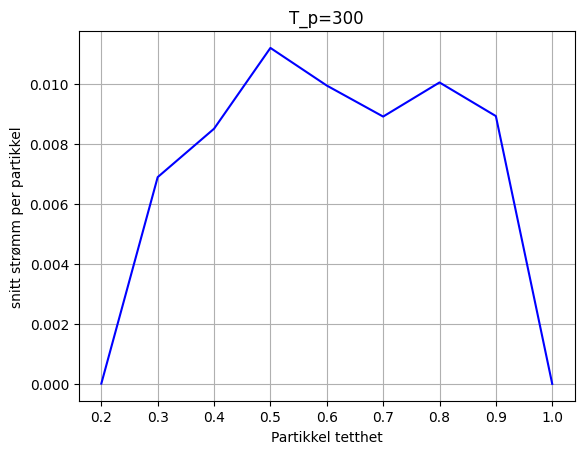

In [32]:
plt.figure("T_p")
plt.title("T_p=300")
plt.plot(rho,cur_rho, color="blue")
plt.xlabel("Partikkel tetthet")
plt.ylabel("snitt strømm per partikkel")
plt.grid()
plt.show()

### Diskusjon:
Først ser en at ved veldig høy tetthet blir strømmen veldig lav. Dette er et resultat av partiklene trenger åpne festepunkter å bevege seg til, men siden partikkeltettheten er så høy er det få partikler som har muligheten til å bevege seg. I tillegg er strømmen normalisert for antall partikler slik at den blir enda mindre relativt. Videre ser vi at generelt flere partikler forårsaker mindre partikkelstrøm. Dette kan knyttes til effekten som vi beskrev i 4a der partikkelinteraksjonen gjør at det ofte kun er én partikkel som kommer seg videre, derfor vil middlingen over antall partikler forårsake at flere partikler har mindre strøm. Ser en på absolutt strøm vil litt høyere partikkeltetthet gjøre det bedre enn de laveste, antageligvis på grunn av den andre effekten nevnt tidligere, der sannsynligheten for at én partikkel hopper til neste potensialgrop er høyere når det er noen andre partikler i gropen som stopper den i å bevege seg bakover. 

## Oppgave 4c

In [12]:
# Definerer ny lavere T_p
T_p= 150
cycles = int(30000/T_p)

# lager et array for å lagre resultater
cur_rho_lowerT_p=np.zeros_like(N_p)

# Kjører simulering for alle partikkel antall, Samme som i 4b
for i in range(len(N_p)):
    startPositions=np.int_(np.floor(np.linspace(0,N_x*spatialPeriods,int(N_p[i]))))
    x, currents, XX=simulate4(startPositions,alpha,T_p,N_x,int(N_p[i]),k,b,h,spatialPeriods,cycles,startV_2)
    cur_rho_lowerT_p[i]=np.mean(currents)

runnning half-cycles: 100%|##########| 400/400 [00:07<00:00, 54.43it/s]


In [13]:
# Definerer ny høyere T_p
T_p= 500
cycles = int(30000/T_p)

# lager et array for å lagre resultater
cur_rho_higherT_p=np.zeros_like(rho)

# Kjører simulering for alle partikkel antall, Samme som i 4b
for i in range(len(N_p)):
    startPositions=np.int_(np.floor(np.linspace(0,N_x*spatialPeriods,int(N_p[i]))))
    x, currents, XX=simulate4(startPositions,alpha,T_p,N_x,int(N_p[i]),k,b,h,spatialPeriods,cycles,startV_2)
    cur_rho_higherT_p[i]=np.mean(currents)

runnning half-cycles: 100%|##########| 120/120 [00:07<00:00, 15.28it/s]


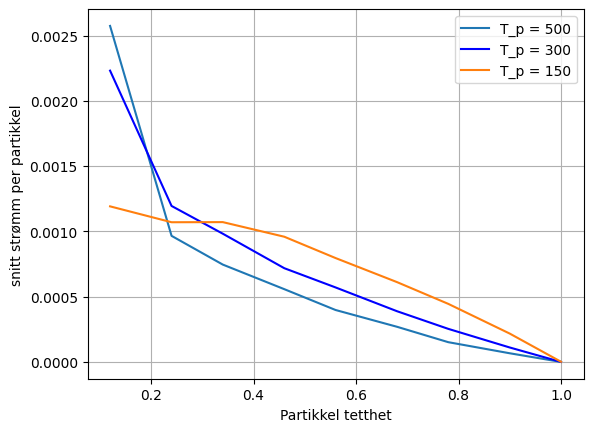

In [20]:
plt.plot(rho,cur_rho_higherT_p,label="T_p = 500")
plt.plot(rho,cur_rho, label="T_p = 300",color="blue")
plt.plot(rho,cur_rho_lowerT_p,label="T_p = 150")
plt.xlabel("Partikkel tetthet")
plt.ylabel("snitt strømm per partikkel")
plt.grid()
plt.legend()
plt.show()

### Diskusjon:
Totalt ser en to effekter her. For høy tetthet er kortere syklus bedre, men for lav tetthet er både lengre syklus og kortere syklus dårligere. Grunnen til at kortere syklus gir bedre resultat for høy tetthet, kommer igjen fra effekten ved at høy tetthet gir høy sannsynlighet for at én partikkel hopper til neste potensialgrop. Siden det uansett er slik at det sannsynligvis bare er én partikkel som hopper til neste grop per syklus, vil kortere syklus og dermed flere sykluser gi høyere partikkelstrøm. Selvfølgelig vil dette nå én grense der for kort syklus blir værre igjen, men simulering gjør det tydelig at for forskjellige tettheter er forskjellige sykluslengder optimale. 

For lav tetthet er syklus varighet på 200 tidsteg som var best. Dette skyldes at ved lav tetthet vil partikkelinteraksjonen spille mindre rolle, ettersom det skjer oftere, og dermed vil det oppføre seg likere simuleringen uten partikkelinteraksjon. Da handler optimalisering av syklus varighet mer om tiden det tar for sannsynlighetsfordelingen til posisjonen av partikkelen i én grop blir tilstrekkelig fordelt. For kort syklus så blir sannsynligheten fordelingen klumpet rundt utgangsposisjonen, som er i potensialgropen partikkelen befant seg i. Derfor når potensialet bytter tilbake til ratchet potensialet så  rekker ikke partikkelen til neste potensialgrop, og strømmen blir lavere. Ved for lang syklus så vil ikke flere partikler komme til neste strøm, fordi sannsynlighetsfordelingen til partiklene blir tilnærmet konstante over tid etterhvert. Det gjør at den ekstra varigheten til syklusen bare blir en slags ventetid, men som vil slå negativt ut på på strømmen på grunn av middlingen over tid. 

## Oppgave 4d

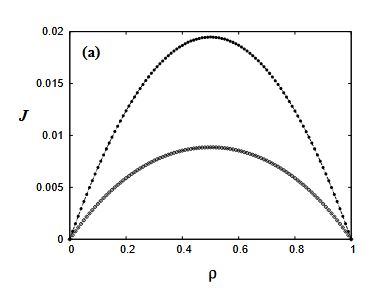

figur 2a i 

Chacko, J. og Tripathy, G.(2015). Interacting particles in disordered flashing ratchets. Indian Journal of Physics, volum 89, 981–988,  hentet fra http://dx.doi.org/10.1007/s12648-015-0660-5


I denne artikkelen så ser de på nesten det helt samme scenarioet som oss, bare at det også inkluderer litt tilfeldig feil i potensialet. Denne figuren derimot er av før de går videre til det de kaller "Disordered flashing rachets". Her plotter det nesten nøyaktig det samme som oss, bare at de plotter den ikke normaliserte strømmen. Metoden deres er også svært lik, de eneste forskjellene virket å være hvordan variablene deres var definert, men illustrasjonen deres av potensialet var det samme som vi hadde. Under har vi inkludert et plot av våre data for ikke normalisert strøm for å kunne sammenligne bedre.

Det første å bemerke er at deres data er en del glattere en våre, der de antagelig har kjørt litt flere simuleringer. Aksene våre er svært like noe som tyder på at selve utregningen har blitt riktig. Videre så er grafen vår for syklus varighet på 300 tidsteg ganske lik deres, der begge ser ut som et toppunkt i et polynom. Derimot er de andre grafene, spesielt for syklus varighet på 150, mer ulik svaret i artikkelen. I artikkelen leste vi at de brukte en frekvens på $\omega =0.05$ per montecarlo tidsteg, som vi antar vil tilsvare $T_{p} = \frac{1}{\omega} = 20$. Til å begynne med virker det som større enn oss, men siden de har $N_{x}= 6$, så er $T_{p} = 20$ høyt nok til at partiklene vil være fordelt etter at det konstante potensialet har virket. Forholdet er $\frac{T_{p}}{N_{x}}=\frac{10}{3}$, som er større enn vårt på $\frac{T_{p}}{N_{x}}=\frac{3}{2}$. Som beskrevet i oppgave 4c rekker ikke partiklene i vår simulasjon å fordele seg, mens deres simulering er designet slik at det alltid skal skje. Det gir da mening at dataene vår ikke stemmer så bra med deres i dette tilfellet. 

Totalt synes vi at vår data matchet bra med deres og de siste feilene i verdi for grafen med $T_{p} = 300$ antageligvis skyldes noen andre forskjeller i definerte variabler. Vi klarte ikke å få full oversikt over hvilke variabler i artikkelen som tilsvarer våre. 

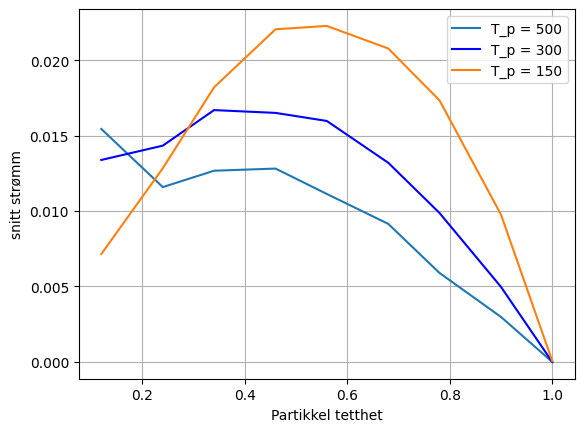

In [19]:
plt.plot(rho,cur_rho_higherT_p*N_p,label="T_p = 500")
plt.plot(rho,cur_rho*N_p, label="T_p = 300",color="blue")
plt.plot(rho,cur_rho_lowerT_p*N_p,label="T_p = 150")
plt.xlabel("Partikkel tetthet")
plt.ylabel("snitt strømm")
plt.grid()
plt.legend()
plt.show()